# Rossmann Store Sales — 02 Forecasting models: per-store vs global
**Goal:** forecast daily sales of 1,115 drugstores for the last 6 weeks of the data and compare
a **global** model (one LightGBM for all stores) with **per-store** models, using **RMSPE** and **sMAPE** on a
time-based hold-out.

| Step | What | Code |
|---|---|---|
| 1 | Load `clean.parquet` (notebook 01) and build the feature panel | `rossmann.data`, `rossmann.features` |
| 2 | Evaluation design: hold-out = last 42 days, inner validation = 42 days before it, 3 rolling origins | `rossmann.models.Split` |
| 3 | Models: 2 baselines, 3 per-store models, 1 global model | `rossmann.models` |
| 4 | Results: accuracy, per-store comparison, horizon, segments, feature importance | `outputs/metrics/*.csv` |
| 5 | Kaggle submission | `outputs/submission.csv` |

The heavy training (~35 min on 2 CPU cores) is done by `python run_pipeline.py`, which writes everything to
`outputs/`. This notebook reads those results; set `RUN_PIPELINE = True` to retrain from scratch inside the notebook.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
from IPython.display import Image, display, Markdown
from rossmann import config, data, features as F, models as M, metrics as MET, effects as E, pipeline

pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
MET_DIR, FIG_DIR = config.MET_DIR, config.FIG_DIR
print("repo:", ROOT.name)

repo: rossmann-sales-forecasting


In [2]:
RUN_PIPELINE = False          # True = retrain everything (~35 min); False = load outputs/ of the last run
if RUN_PIPELINE or not (config.OUT_DIR / "summary.json").exists():
    pipeline.main(["--raw-dir", str(config.RAW_DIR)])
summary = json.loads((config.OUT_DIR / "summary.json").read_text())
summary["data"]

{'rows': 1017209,
 'stores': 1115,
 'date_min': '2013-01-01',
 'date_max': '2015-07-31',
 'closed_share': 0.16989330609540418,
 'open_zero_sales': 54,
 'extreme_outliers': 1113,
 'stores_with_gap': 181,
 'mean_sales_open': 6955.959133664481,
 'median_sales_open': 6369.0,
 'total_sales': 5873180623.0}

## 1. Feature panel
`build_panel` puts train **and** Kaggle test rows on a complete store × day grid (so "days since / until" features
are right even across the Jul–Dec 2014 gap of 180 stores) and adds features that are **known in advance** for any
future day:

| Group | Features |
|---|---|
| Calendar | weekday, day, month, year, ISO week, day of year, linear trend `t` |
| Promo | `Promo`, position inside the promo run (`promo_day`), promo next / last week, Promo2 active, weeks in Promo2, Promo2 month |
| Holidays | state-holiday type, school holiday, days to / since state holiday, Christmas, Easter, school holiday; holidays this / next week |
| Openings | days since / until a closed day, length of the previous / next closure (refurbishments) |
| Store | store id (categorical), type, assortment, log competition distance, months since competitor opened |
| Store history | mean log sales, weekday profile, promo lift, mean customers, Sunday opening — **computed only from the training window** |

`Customers` is not used as a feature: it is unknown for future days.

In [3]:
panel = pd.read_parquet(config.DATA_DIR / "panel.parquet") if (config.DATA_DIR / "panel.parquet").exists() \
    else pipeline.prepare(config.RAW_DIR)[3]
print(f"panel: {len(panel):,} rows ({(panel.is_test == 1).sum():,} Kaggle test rows), {panel.Store.nunique()} stores")
print("global model features:", len(F.GLOBAL_FEATURES), "| per-store model features:", len(F.LOCAL_FEATURES))
cols = ["Date", "Open", "Promo", "promo_day", "PromoNextWeek", "StateHoliday", "days_to_holiday",
        "days_since_holiday", "days_to_christmas", "days_since_closed", "prev_closed_len"]
panel.loc[(panel.Store == 1) & panel.Date.between("2014-12-19", "2015-01-03"), cols]

panel: 1,058,297 rows (41,088 Kaggle test rows), 1115 stores
global model features: 42 | per-store model features: 31


,Date,Open,Promo,promo_day,PromoNextWeek,StateHoliday,days_to_holiday,days_since_holiday,days_to_christmas,days_since_closed,prev_closed_len
717,2014-12-19,1,1,5,0,0,6.0000,30.0000,6,5.0000,1.0000
718,2014-12-20,1,0,0,0,0,5.0000,30.0000,5,6.0000,1.0000
719,2014-12-21,0,0,0,0,0,4.0000,30.0000,4,0.0000,1.0000
720,2014-12-22,1,0,0,0,0,3.0000,30.0000,3,1.0000,1.0000
721,2014-12-23,1,0,0,0,0,2.0000,30.0000,2,2.0000,1.0000
722,2014-12-24,1,0,0,0,0,1.0000,30.0000,1,3.0000,1.0000
723,2014-12-25,0,0,0,0,c,0.0000,0.0000,0,0.0000,2.0000
724,2014-12-26,0,0,0,0,c,0.0000,0.0000,60,0.0000,2.0000
725,2014-12-27,1,0,0,0,0,5.0000,1.0000,60,1.0000,2.0000
726,2014-12-28,0,0,0,0,0,4.0000,2.0000,60,0.0000,1.0000


## 2. Evaluation design
* **Hold-out (F1):** 2015-06-20 → 2015-07-31, the last 42 days (6 full weeks) — never used for any choice.
* **Inner validation:** the 42 days before the hold-out; used only for early stopping (number of trees) and for
  testing an RMSPE correction factor. Models are then **refit on all data before the hold-out**.
* **Rolling origin:** the same procedure repeated for F2 (9 May – 19 Jun 2015) and F3 (28 Mar – 8 May 2015, contains Easter and 1 May).
* **Metrics** on open days with sales > 0 (Kaggle convention; closed days are known and forecast as 0):

$$\text{RMSPE}=\sqrt{\frac{1}{n}\sum_i\left(\frac{y_i-\hat y_i}{y_i}\right)^2}\qquad
\text{sMAPE}=\frac{100}{n}\sum_i\frac{2\,|y_i-\hat y_i|}{|y_i|+|\hat y_i|}$$

inner validation: 2015-05-09 -> 2015-06-19
hold-out        : 2015-06-20 -> 2015-07-31


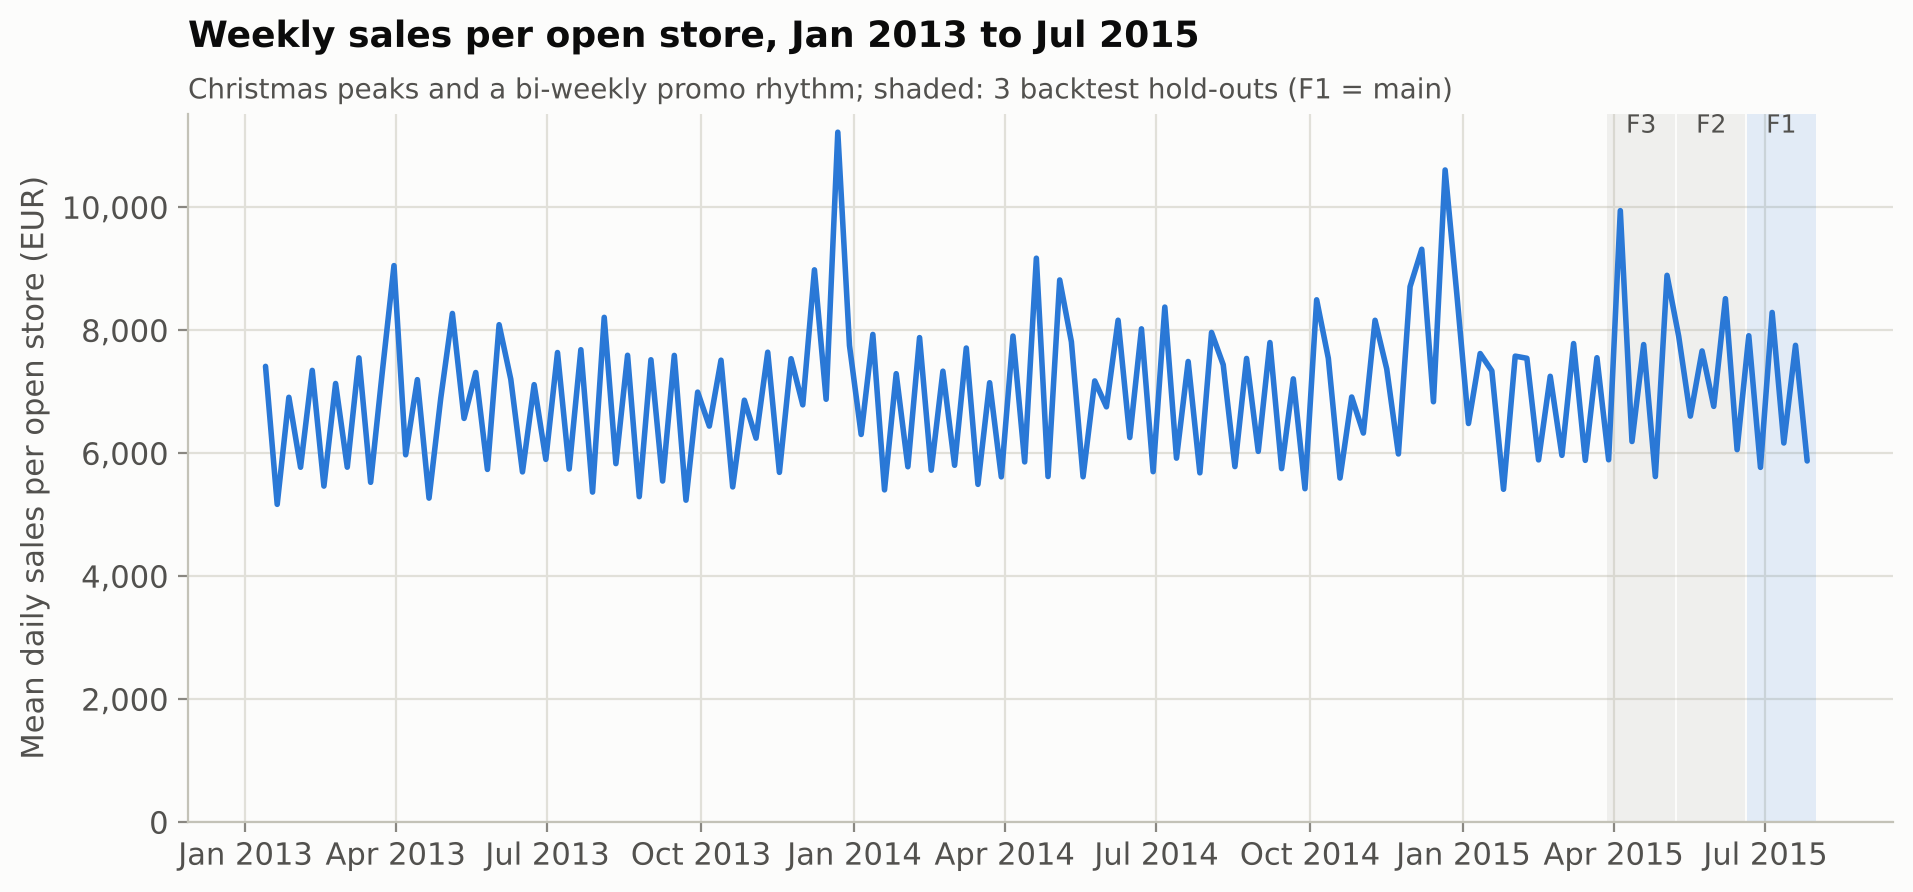

In [4]:
split = M.Split()
print("inner validation:", split.valid_start.date(), "->", (split.holdout_start - pd.Timedelta(days=1)).date())
print("hold-out        :", split.holdout_start.date(), "->", split.holdout_end.date())
display(Image(FIG_DIR / "fig01_sales_overview.png", width=900))

## 3. Models
| Model | Type | Idea |
|---|---|---|
| Seasonal naive | per store | last observed sales of the same weekday (lag-7 logic suggested by the ACF in notebook 01) |
| Weekday × promo profile | per store | geometric mean of the last 12 months per store × weekday × promo |
| Per-store SARIMAX | per store, statsmodels | log sales = regression on calendar/promo/holiday dummies + ARMA(1,1) errors; closed days are missing values for the Kalman filter. 150 random stores (slow). |
| Per-store ridge | per store, scikit-learn | ~120 one-hot calendar / promo / holiday-distance features, L2 penalty |
| Per-store LightGBM | per store | 1,115 small boosted-tree models (15 leaves); number of trees chosen on the inner validation |
| **Global LightGBM** | one model | all stores pooled, store id + store history features, 127 leaves, early stopping |

All learned models are trained on `log1p(Sales)` of open days, so the squared error is close to a relative error.

## 4. Results on the main hold-out (F1)

In [5]:
met = pd.read_csv(MET_DIR / "backtest_metrics.csv")
f1 = met[met.fold == "F1"].set_index("model")[["RMSPE", "sMAPE", "MAPE", "MAE", "Bias_%", "train_seconds", "n_models", "n_eval_days"]]
f1.sort_values("RMSPE")

,RMSPE,sMAPE,MAPE,MAE,Bias_%,train_seconds,n_models,n_eval_days
model,,,,,,,,
Global LightGBM,0.1073,7.6612,7.8287,524.7486,0.4326,243.8000,1,40282
Per-store LightGBM,0.1149,8.0403,8.2456,555.2965,0.5018,132.2000,1115,40282
Per-store ridge regression,0.1245,8.9173,9.0739,622.2625,-0.0169,6.8000,1115,40282
Store x weekday x promo profile,0.1347,9.7722,9.8550,677.7017,-1.0283,0.1000,1115,40282
Per-store SARIMAX (ARMA errors),0.1400,10.4177,10.5307,740.9301,-1.1546,238.7000,150,5424
Seasonal naive (last same weekday),0.3494,20.1952,24.1908,"1,484.5310",13.5925,0.3000,1115,40282


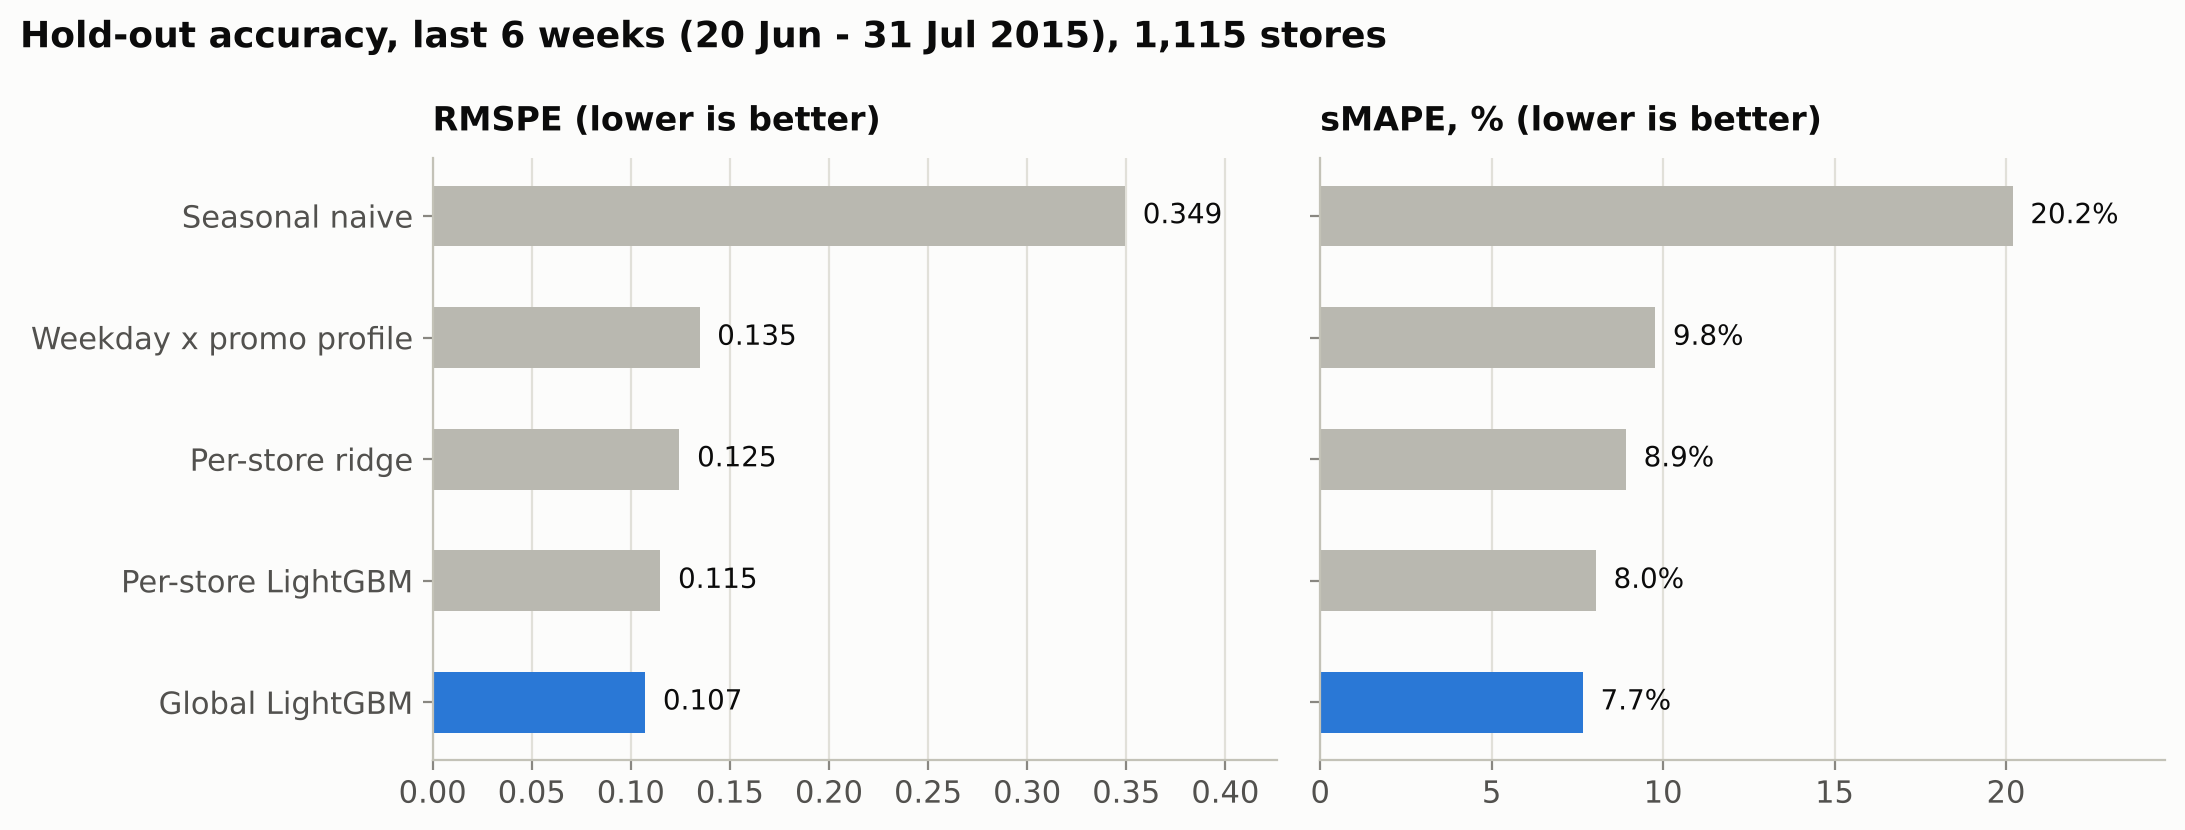

In [6]:
display(Image(FIG_DIR / "fig02_model_comparison.png", width=900))

### Robustness: three rolling-origin hold-outs

fold,F1,F2,F3,mean
model,,,,
Global LightGBM,0.1073,0.0949,0.0961,0.0995
Per-store LightGBM,0.1149,0.1063,0.1280,0.1164
Per-store ridge regression,0.1245,0.1147,0.1124,0.1172
Per-store SARIMAX (ARMA errors),0.1400,NaN,NaN,0.1400
Store x weekday x promo profile,0.1347,0.1399,0.1584,0.1443
Seasonal naive (last same weekday),0.3494,0.3034,0.2926,0.3151


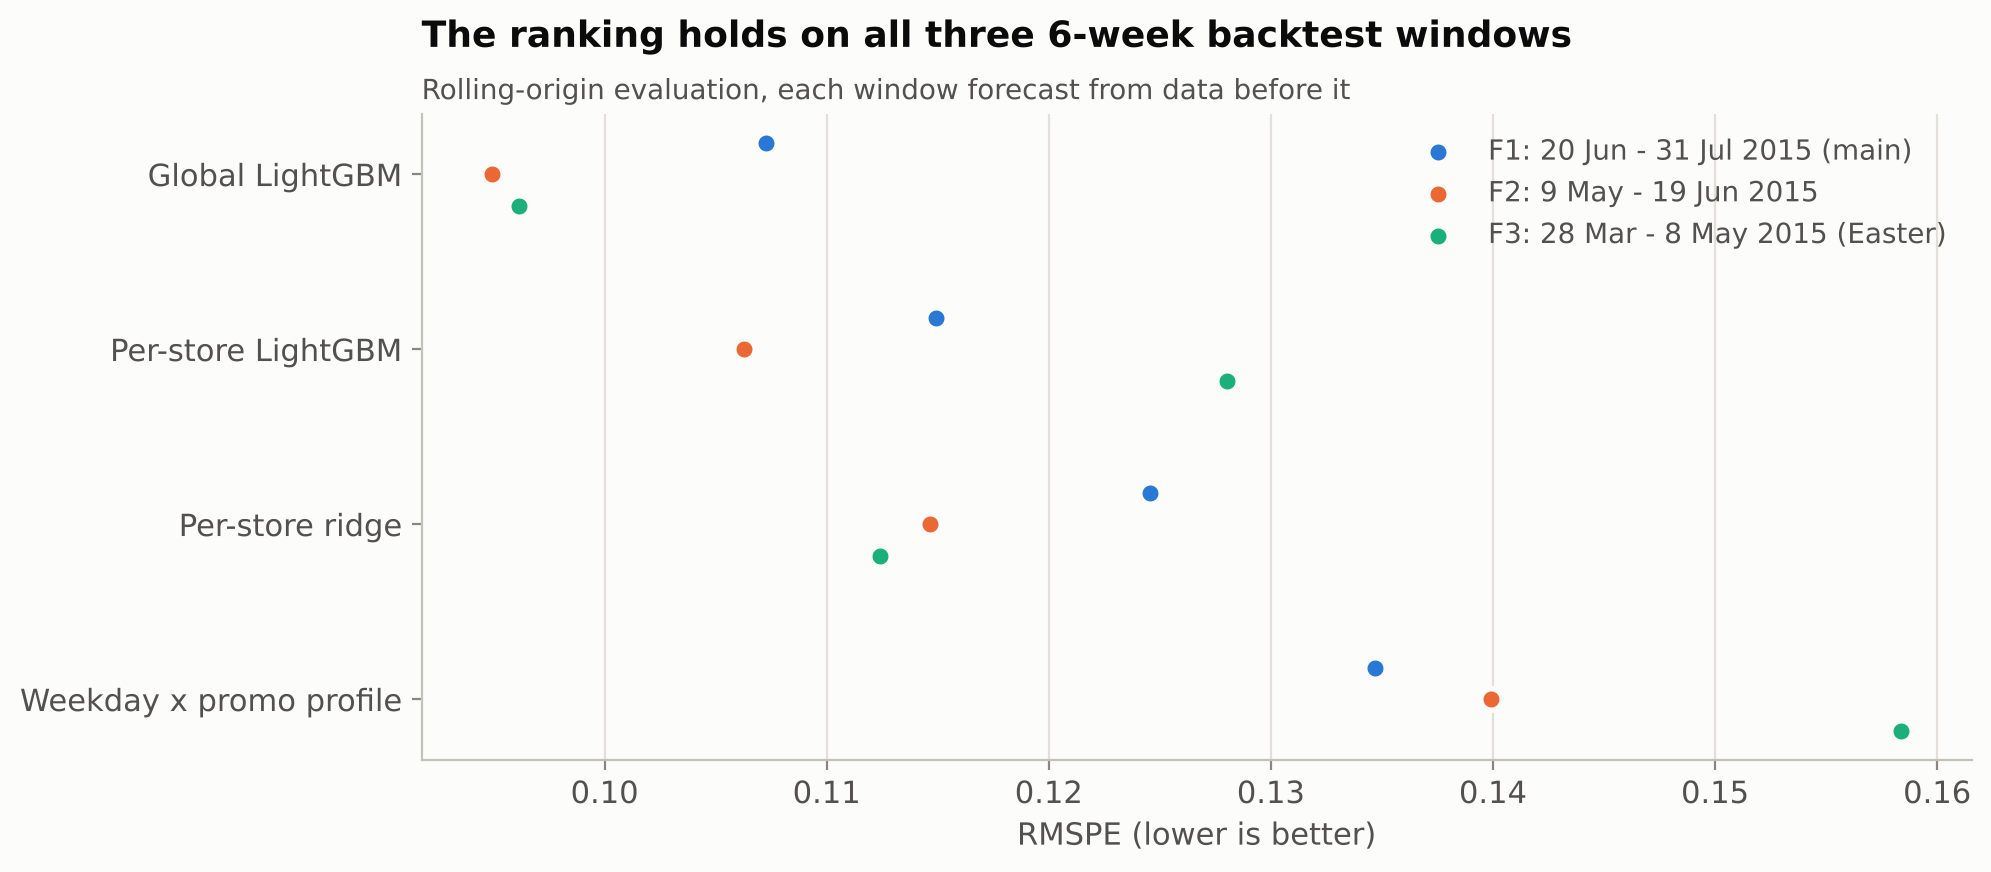

In [7]:
tab = met.pivot_table(index="model", columns="fold", values="RMSPE")
tab["mean"] = tab.mean(axis=1)
display(tab.sort_values("mean"))
display(Image(FIG_DIR / "fig03_backtest_folds.png", width=850))

### SARIMAX sample
SARIMAX is fitted per store with a state-space model and is too slow for all 1,115 stores, so all models are compared on the
same random sample of 150 stores.

In [8]:
pd.read_csv(MET_DIR / "sample_metrics.csv").set_index("model")[["RMSPE", "sMAPE", "MAE", "Bias_%"]].sort_values("RMSPE")

,RMSPE,sMAPE,MAE,Bias_%
model,,,,
Global LightGBM,0.1045,7.6803,538.4798,0.5244
Per-store LightGBM,0.1119,8.1808,581.8870,0.6235
Per-store ridge regression,0.1240,9.1923,652.2617,0.0228
Store x weekday x promo profile,0.1284,9.7081,695.3730,-1.2671
Per-store SARIMAX (ARMA errors),0.1400,10.4177,740.9301,-1.1546
Seasonal naive (last same weekday),0.3514,20.6352,"1,549.5531",13.7406


## 5. Per-store vs global

Global LightGBM better than per-store LightGBM for 66.5% of stores
Global LightGBM better than per-store ridge     for 83.2% of stores


,count,mean,std,min,25%,50%,75%,90%,max
model,,,,,,,,,
Global LightGBM,"1,115.0000",0.1013,0.0400,0.0534,0.0806,0.0935,0.1116,0.1339,0.6668
Per-store LightGBM,"1,115.0000",0.1067,0.0515,0.0510,0.0840,0.0981,0.1165,0.1392,1.1177
Per-store ridge regression,"1,115.0000",0.1159,0.0527,0.0520,0.0910,0.1056,0.1263,0.1546,0.9069


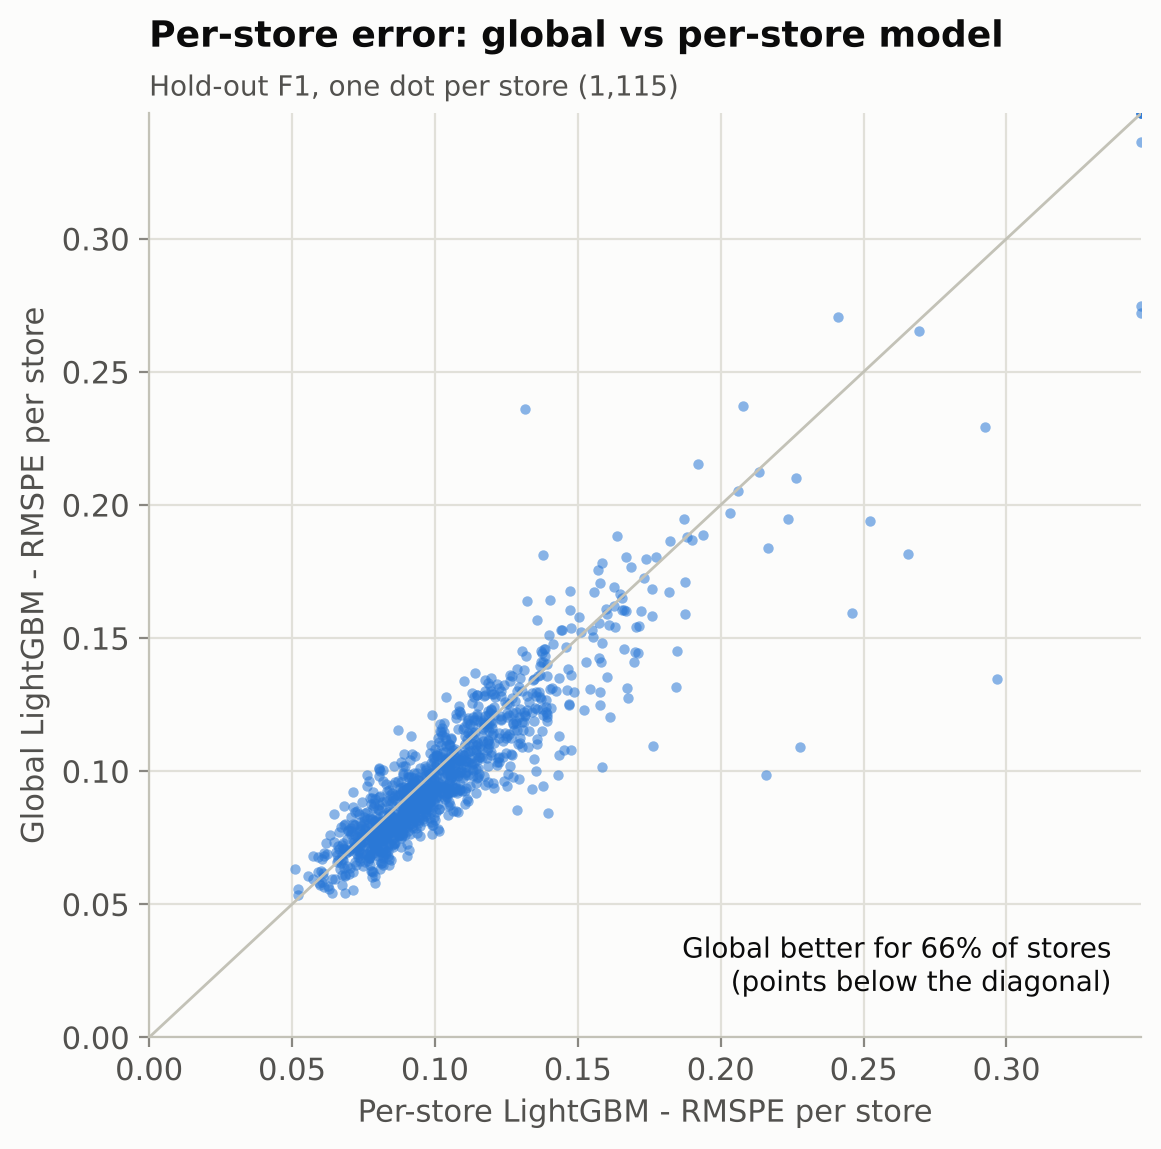

In [9]:
ps = pd.read_csv(MET_DIR / "per_store.csv")
w = ps.pivot(index="Store", columns="model", values="RMSPE")
print(f"Global LightGBM better than per-store LightGBM for {(w['Global LightGBM'] < w['Per-store LightGBM']).mean():.1%} of stores")
print(f"Global LightGBM better than per-store ridge     for {(w['Global LightGBM'] < w['Per-store ridge regression']).mean():.1%} of stores")
display(w[["Global LightGBM", "Per-store LightGBM", "Per-store ridge regression"]].describe(percentiles=[.25, .5, .75, .9]).T)
display(Image(FIG_DIR / "fig04_per_store_global_vs_local.png", width=520))

In [10]:
seg = pd.read_csv(MET_DIR / "segments.csv")
seg.pivot_table(index="segment", columns="model", values="RMSPE")[
    ["Global LightGBM", "Per-store LightGBM", "Per-store ridge regression", "Store x weekday x promo profile"]].round(4)

model,Global LightGBM,Per-store LightGBM,Per-store ridge regression,Store x weekday x promo profile
segment,,,,
All open days,0.1073,0.1149,0.1245,0.1347
Non-promo days,0.1112,0.1163,0.1226,0.1362
Promo days,0.1016,0.1129,0.1272,0.1325
School holiday,0.0982,0.1084,0.1187,0.1277
Store type a,0.1093,0.1193,0.1267,0.1416
Store type b,0.0826,0.0841,0.1133,0.1179
Store type c,0.1108,0.1171,0.1320,0.1394
Store type d,0.1034,0.1076,0.1179,0.1205
Stores with 2014 gap,0.1186,0.1295,0.1406,0.1365


### Error by forecast horizon

model,Global LightGBM,Per-store LightGBM,Per-store ridge regression,Seasonal naive (last same weekday),Store x weekday x promo profile
week,,,,,
1,0.1005,0.1058,0.1109,0.5170,0.1193
2,0.1089,0.1212,0.1398,0.1452,0.1483
3,0.1210,0.1312,0.1320,0.4286,0.1433
4,0.1039,0.1087,0.1176,0.1301,0.1182
5,0.0955,0.1025,0.1091,0.4646,0.1222
6,0.1120,0.1176,0.1344,0.1662,0.1522


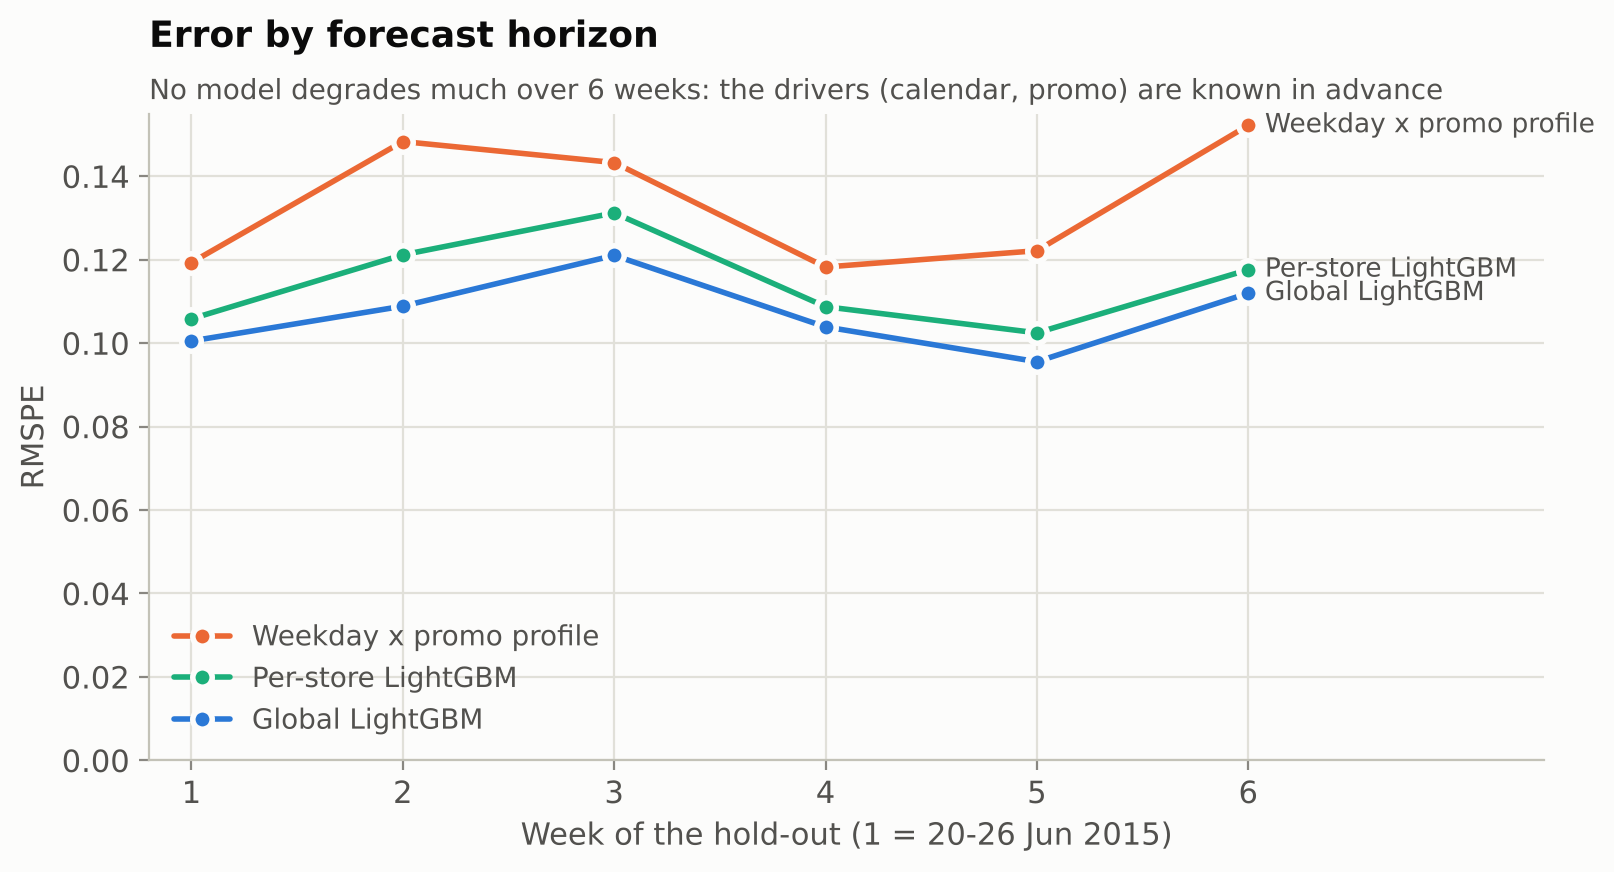

In [11]:
bw = pd.read_csv(MET_DIR / "by_week.csv")
display(bw.pivot_table(index="week", columns="model", values="RMSPE").round(4))
display(Image(FIG_DIR / "fig05_error_by_week.png", width=800))

### Forecasts vs actuals

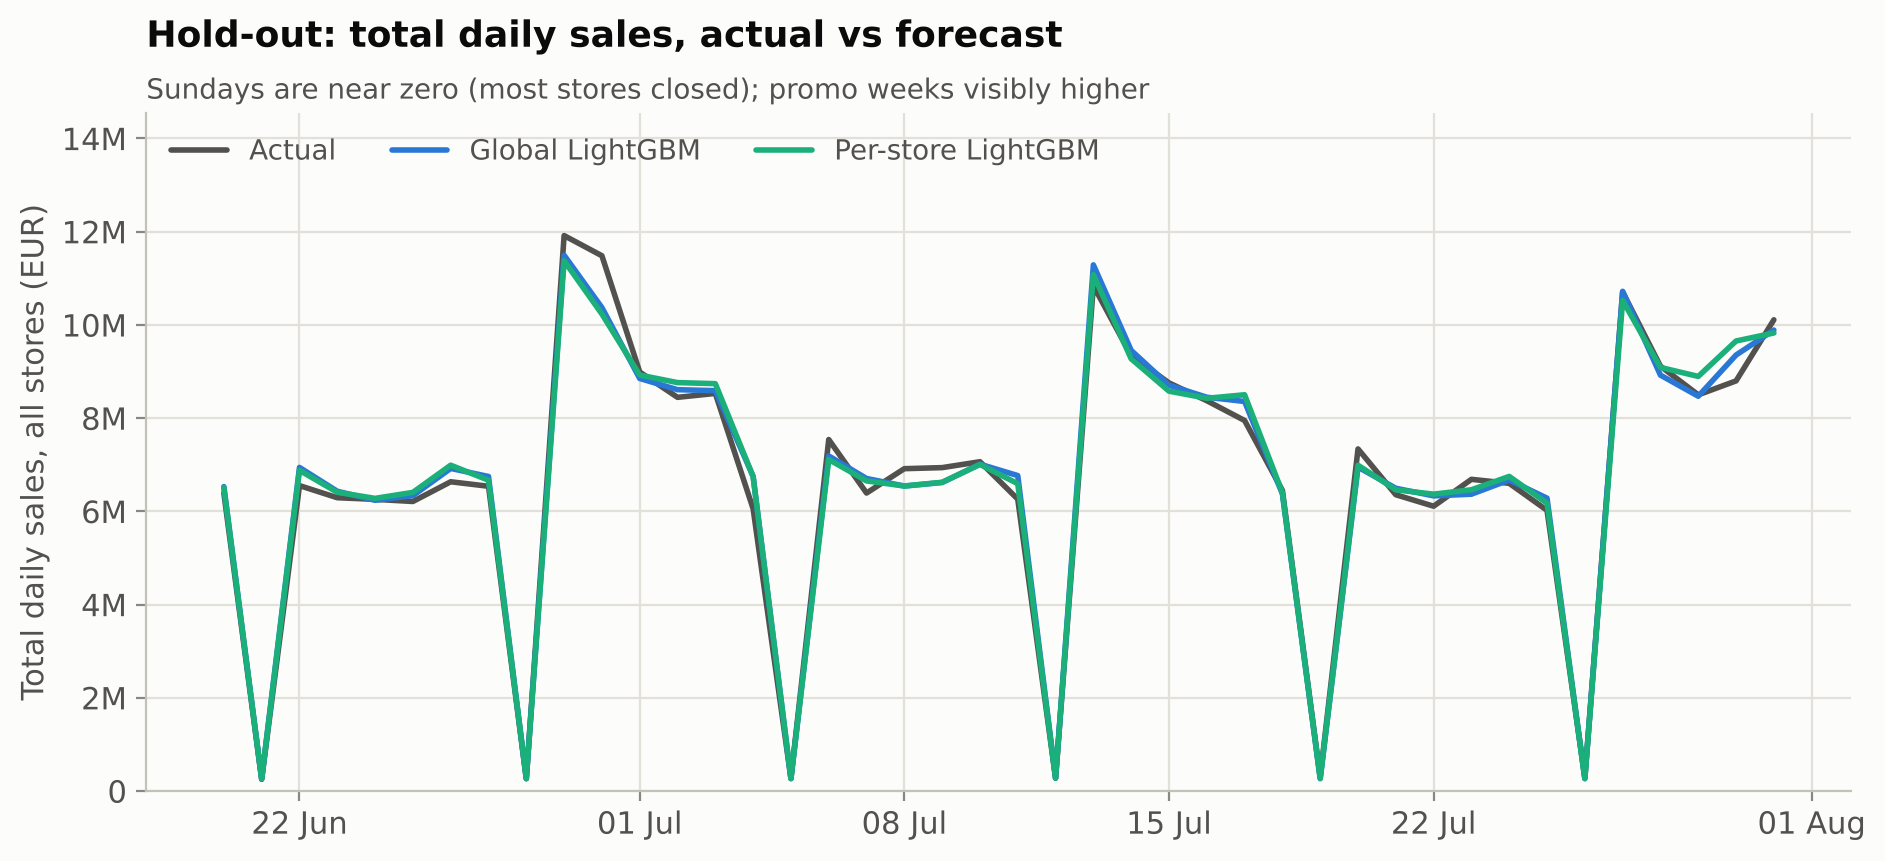

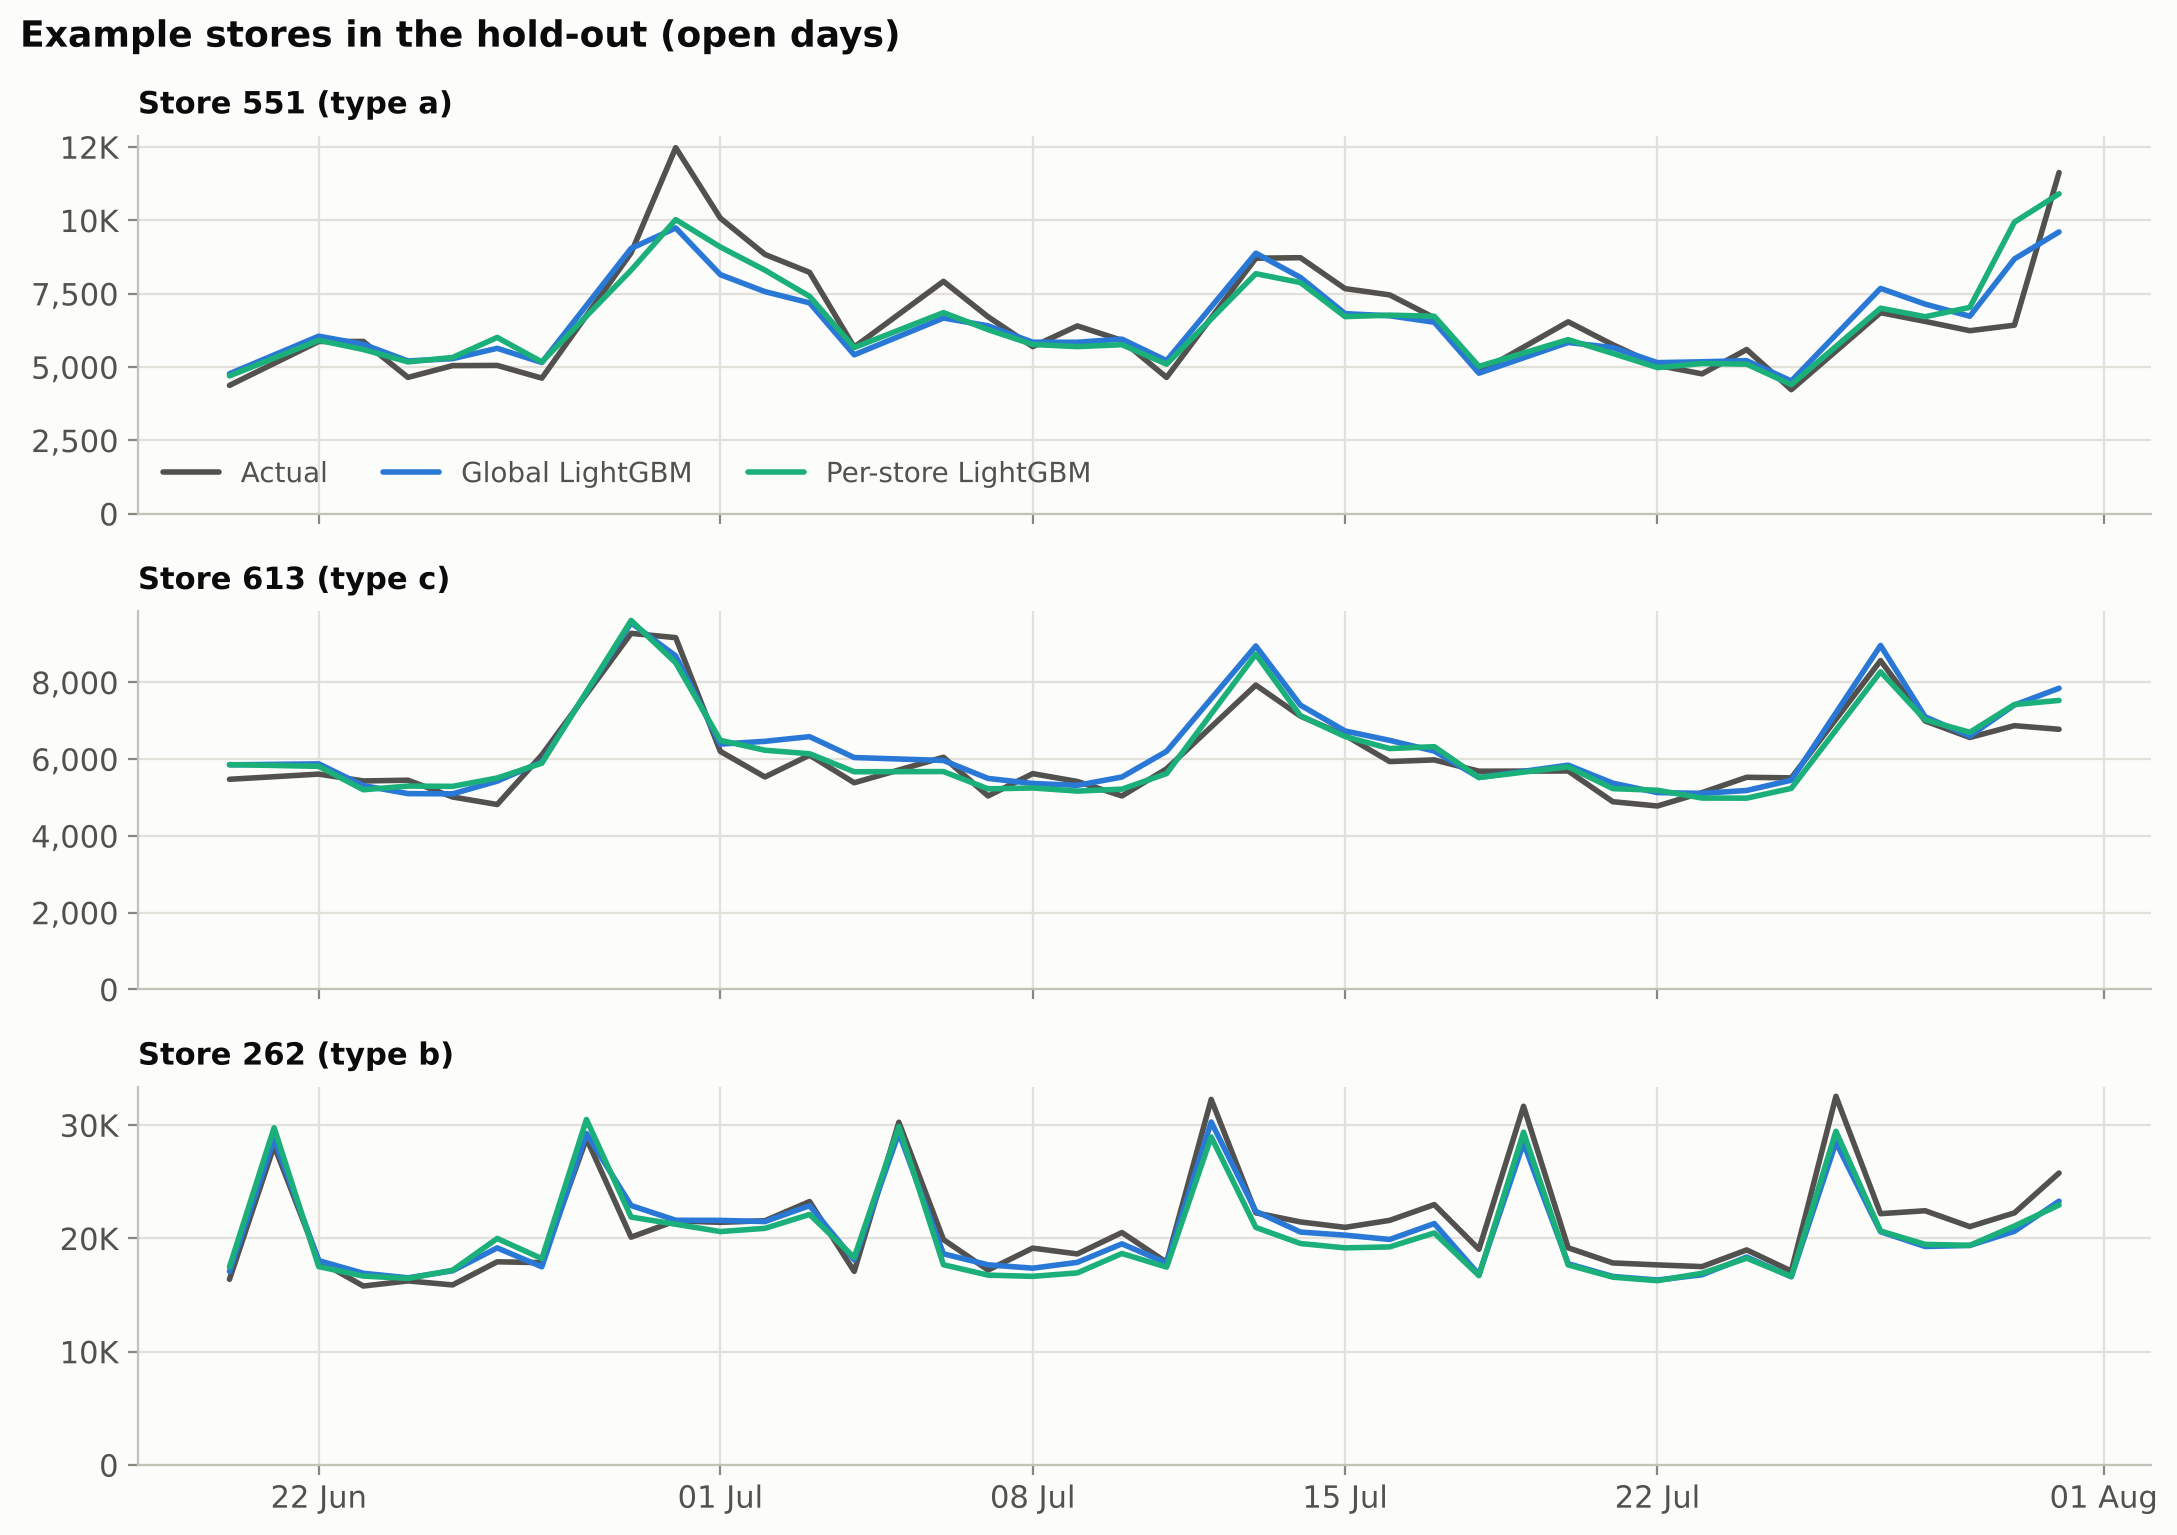

Interactive version (store selector): outputs/figures/interactive_holdout_forecast.html


In [12]:
display(Image(FIG_DIR / "fig06_holdout_total.png", width=900))
display(Image(FIG_DIR / "fig07_store_examples.png", width=900))
print("Interactive version (store selector): outputs/figures/interactive_holdout_forecast.html")

### What drives the global model

,gain_share
group,
store,0.7100
promo,0.1771
calendar,0.0536
holiday,0.0335
closure,0.0257


,group,mean_abs_contrib
0,store,0.2675
1,promo,0.1484
2,calendar,0.0608
3,holiday,0.0235
4,closure,0.0208


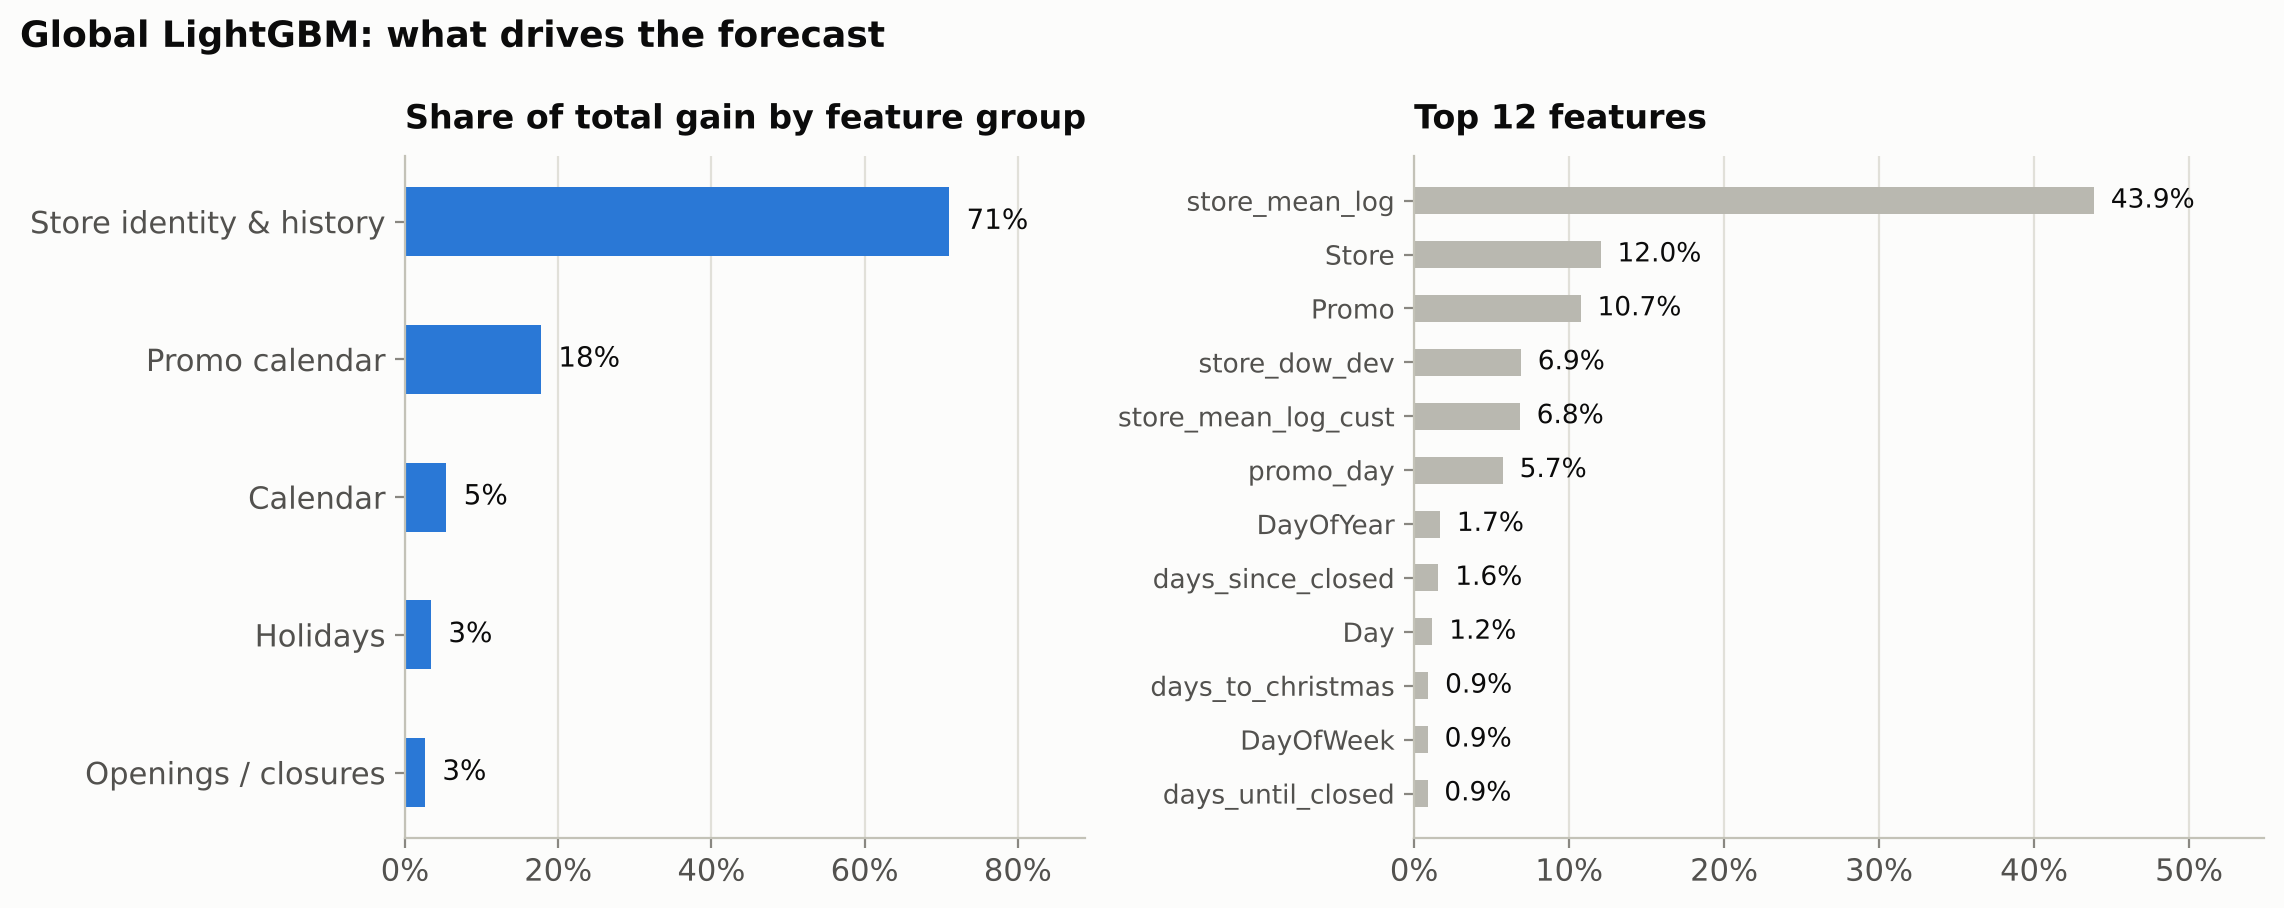

In [13]:
imp = pd.read_csv(MET_DIR / "importance.csv")
display(imp.groupby("group")["gain_share"].sum().sort_values(ascending=False).to_frame())
display(pd.read_csv(MET_DIR / "shap_groups.csv"))
display(Image(FIG_DIR / "fig08_feature_importance.png", width=900))

### RMSPE correction factor (sensitivity check)
RMSPE punishes over-forecasts more than under-forecasts, so Kaggle solutions often multiplied predictions by a factor
slightly below 1. We chose the factor on the **inner validation** window only and checked it on the hold-out.

In [14]:
g = summary["global_info"]
print(f"trees: {g['best_iter']} (early stopping) -> {g['n_trees']} after refit")
print(f"factor chosen on validation: {g['correction']:.4f} | validation RMSPE {g['valid_RMSPE']:.4f} -> {g['valid_RMSPE_corrected']:.4f}")
print("hold-out RMSPE without factor:", round(summary['metrics_F1']['Global LightGBM']['RMSPE'], 4),
      "| with factor:", round(summary['global_corrected_holdout']['RMSPE'], 4))

trees: 1879 (early stopping) -> 1973 after refit
factor chosen on validation: 1.0125 | validation RMSPE 0.0949 -> 0.0942
hold-out RMSPE without factor: 0.1073 | with factor: 0.1113


## 6. Kaggle submission

In [15]:
sub = pd.read_csv(config.OUT_DIR / "submission.csv")
print(sub.shape, "| share of zero forecasts (closed):", round((sub.Sales == 0).mean(), 3))
print(summary.get("submission"))
sub.head()

(41088, 2) | share of zero forecasts (closed): 0.146
{'rows': 41088, 'n_trees': 2067, 'mean_sales_open': 6907.679112020146}


,Id,Sales
0,1,"4,344.1324"
1,2,"7,659.8512"
2,3,"9,172.7919"
3,4,"7,961.6861"
4,5,"7,335.2677"


## 7. Findings
* **Global LightGBM is the most accurate model**: RMSPE 0.107 and sMAPE 7.7% on the 6-week hold-out (20 Jun – 31 Jul 2015), against 0.115 / 8.0% for 1,115 per-store LightGBM models and 0.125 / 8.9% for per-store ridge. It is best in all three backtest windows (mean RMSPE 0.099).
* **Per-store vs global**: the global model has the lower error for 66% of stores (83% vs per-store ridge) and in every store type; the gain is largest for stores with the 2014 data gap and on promo days.
* **Baselines**: the seasonal naive forecast fails (RMSPE 0.349, bias +13.6%) because the last training week was a promo week; a weekday × promo profile already reaches 0.135.
* **Per-store SARIMAX** (150-store sample) reaches 0.140 vs 0.105 for the global model on the same stores.
* **Horizon**: the error does not grow over the six weeks, because all drivers are known in advance.
* **Correction factor**: the RMSPE factor chosen on the validation window (1.0125) made the hold-out worse (0.107 → 0.111) and is not used.